##DATASET

In [1]:

# Upload Adult dataset

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving adult.data to adult.data
Saving adult.names to adult.names
Saving adult.test to adult.test
Saving Index to Index
Saving old.adult.names to old.adult.names
Uploaded files: ['adult.data', 'adult.names', 'adult.test', 'Index', 'old.adult.names']


In [2]:

#  Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

#  Define column names and load data

columns = [
    'age', 'workclass', 'fnlwgt', 'education',
    'education-num', 'marital-status', 'occupation',
    'relationship', 'race', 'sex', 'capital-gain',
    'capital-loss', 'hours-per-week', 'native-country',
    'income'
]

# Training dataset
train_df = pd.read_csv(
    'adult.data',
    names=columns,
    skipinitialspace=True,
    na_values='?',
    skip_blank_lines=True
)

# Official test dataset
test_df = pd.read_csv(
    'adult.test',
    names=columns,
    skipinitialspace=True,
    na_values='?',
    skiprows=1,
    skip_blank_lines=True
)

# Remove trailing full stop from test labels
train_df['income'] = train_df['income'].str.strip()
test_df['income'] = test_df['income'].str.strip().str.rstrip('.')

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining dataset:")
display(train_df.head())

print("\nTesting dataset:")
display(test_df.head())


Training shape: (32561, 15)
Testing shape: (16281, 15)

Training dataset:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Testing dataset:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [4]:

#  Basic dataset analysis

print("Dataset Information:")
train_df.info()

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nStatistical description:")
display(train_df.describe(include='all'))

print("\nIncome distribution:")
print(train_df['income'].value_counts())

print("\nIncome percentages:")
print(train_df['income'].value_counts(normalize=True) * 100)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB

Missing values:
age                  0
workclass         1836
fnlwgt   

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,32561.000000,30725,3.256100e+04,32561,32561.000000,32561,30718,32561,32561,32561,32561.000000,32561.000000,32561.000000,31978,32561
unique,NaN,8,NaN,16,NaN,7,14,6,5,2,NaN,NaN,NaN,41,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN



Income distribution:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Income percentages:
income
<=50K    75.919044
>50K     24.080956
Name: proportion, dtype: float64


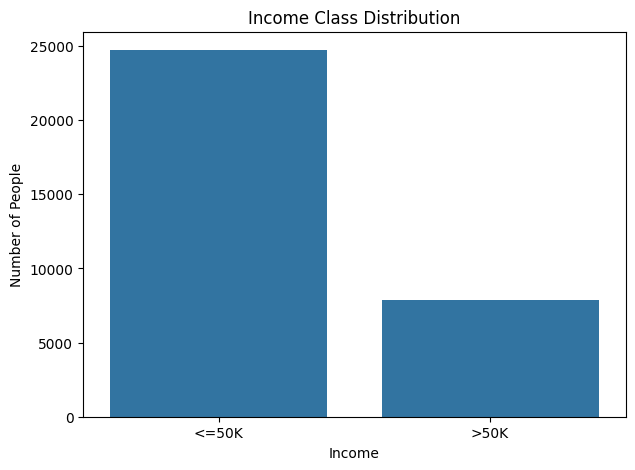

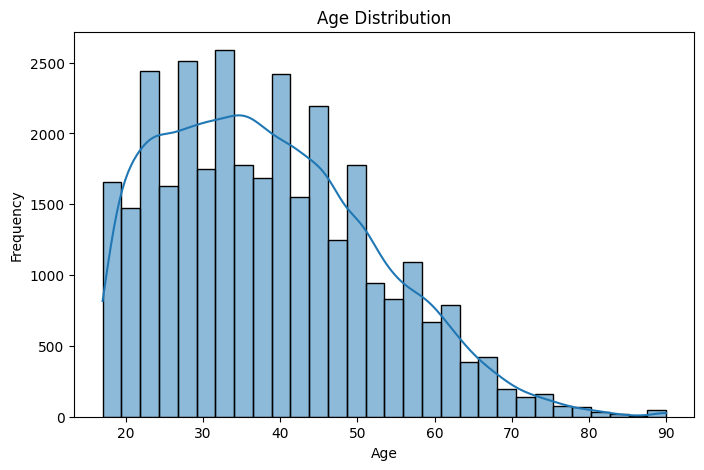

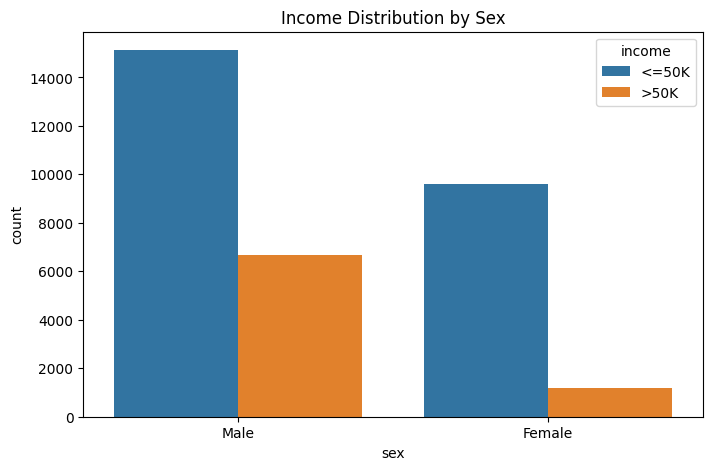

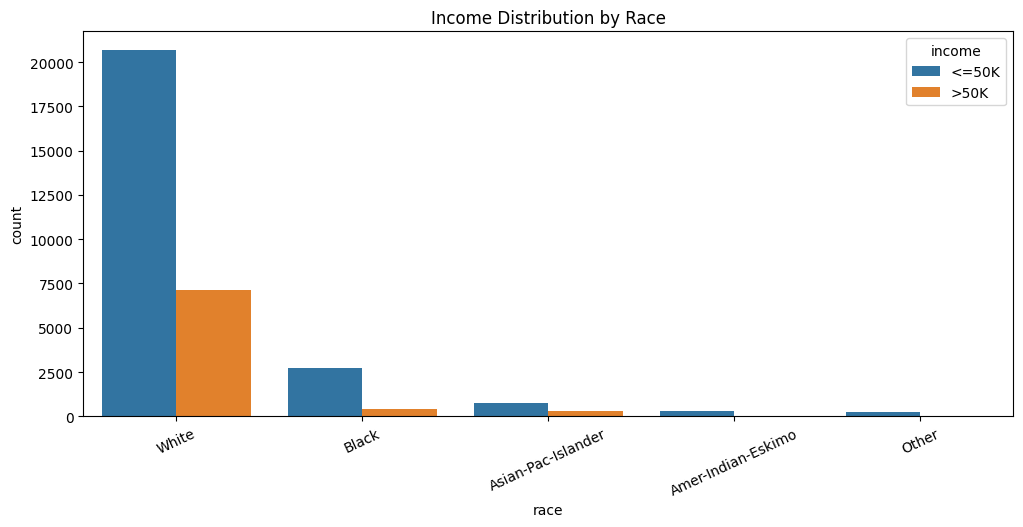

In [5]:

#  Income distribution

plt.figure(figsize=(7,5))

sns.countplot(data=train_df, x='income')

plt.title("Income Class Distribution")
plt.xlabel("Income")
plt.ylabel("Number of People")
plt.show()


# Distribution of age
plt.figure(figsize=(8,5))

sns.histplot(train_df['age'], bins=30, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


# Income distribution by sex
plt.figure(figsize=(8,5))

sns.countplot(data=train_df, x='sex', hue='income')

plt.title("Income Distribution by Sex")
plt.show()


# Income distribution by race
plt.figure(figsize=(12,5))

sns.countplot(data=train_df, x='race', hue='income')

plt.title("Income Distribution by Race")
plt.xticks(rotation=25)
plt.show()


In [6]:

#  Check missing-value percentages

missing = train_df.isnull().sum()

missing_percentage = (missing / len(train_df)) * 100

missing_table = pd.DataFrame({
    'Missing Count': missing,
    'Missing Percentage': missing_percentage
})

display(missing_table.sort_values(
    by='Missing Percentage',
    ascending=False
))


,Missing Count,Missing Percentage
occupation,1843,5.660146
workclass,1836,5.638647
native-country,583,1.790486
fnlwgt,0,0.000000
education,0,0.000000
education-num,0,0.000000
age,0,0.000000
marital-status,0,0.000000
relationship,0,0.000000
sex,0,0.000000


In [7]:

#  Separate features and target

X = train_df.drop('income', axis=1)
y = train_df['income'].map({
    '<=50K': 0,
    '>50K': 1
})

X_test = test_df.drop('income', axis=1)
y_test = test_df['income'].map({
    '<=50K': 0,
    '>50K': 1
})

# Train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Validation samples:", X_val.shape)
print("Official test samples:", X_test.shape)

print("\nIncome distribution:")
print("Train:\n", y_train.value_counts(normalize=True))
print("Validation:\n", y_val.value_counts(normalize=True))
print("Test:\n", y_test.value_counts(normalize=True))


Training samples: (26048, 14)
Validation samples: (6513, 14)
Official test samples: (16281, 14)

Income distribution:
Train:
 income
0    0.759175
1    0.240825
Name: proportion, dtype: float64
Validation:
 income
0    0.759251
1    0.240749
Name: proportion, dtype: float64
Test:
 income
0    0.763774
1    0.236226
Name: proportion, dtype: float64


##BASELINE MODELS(LR AND RF)

In [8]:

# CELL 8: Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Remove duplicate educational representation
X_train_model = X_train.drop(columns=['education-num'])
X_val_model = X_val.drop(columns=['education-num'])
X_test_model = X_test.drop(columns=['education-num'])

# Identify numerical and categorical columns
numeric_features = X_train_model.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train_model.select_dtypes(
    include=['object']
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

print("Preprocessing pipeline created successfully!")


Numerical features: ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Preprocessing pipeline created successfully!


In [9]:

# CELL 9: Logistic Regression

import time

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

lr_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

start = time.time()

lr_model.fit(X_train_model, y_train)

lr_time = time.time() - start

lr_predictions = lr_model.predict(X_val_model)
lr_probabilities = lr_model.predict_proba(X_val_model)[:, 1]

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")

print("Accuracy:", accuracy_score(y_val, lr_predictions))
print("Precision:", precision_score(y_val, lr_predictions))
print("Recall:", recall_score(y_val, lr_predictions))
print("F1 Score:", f1_score(y_val, lr_predictions))
print("ROC-AUC:", roc_auc_score(y_val, lr_probabilities))
print("Training Time:", round(lr_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(y_val, lr_predictions))


LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.855366190695532
Precision: 0.7400306748466258
Recall: 0.6154336734693877
F1 Score: 0.6720055710306406
ROC-AUC: 0.9077813860630197
Training Time: 0.75 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.91      4945
           1       0.74      0.62      0.67      1568

    accuracy                           0.86      6513
   macro avg       0.81      0.77      0.79      6513
weighted avg       0.85      0.86      0.85      6513



In [10]:

# CELL 10: Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    ))
])

start = time.time()

rf_model.fit(X_train_model, y_train)

rf_time = time.time() - start

rf_predictions = rf_model.predict(X_val_model)
rf_probabilities = rf_model.predict_proba(X_val_model)[:, 1]

print("RANDOM FOREST RESULTS")
print("---------------------")

print("Accuracy:", accuracy_score(y_val, rf_predictions))
print("Precision:", precision_score(y_val, rf_predictions))
print("Recall:", recall_score(y_val, rf_predictions))
print("F1 Score:", f1_score(y_val, rf_predictions))
print("ROC-AUC:", roc_auc_score(y_val, rf_probabilities))
print("Training Time:", round(rf_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(y_val, rf_predictions))


RANDOM FOREST RESULTS
---------------------
Accuracy: 0.8595117457392907
Precision: 0.7532971295577967
Recall: 0.6192602040816326
F1 Score: 0.6797339866993349
ROC-AUC: 0.9086180769072036
Training Time: 55.39 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.94      0.91      4945
           1       0.75      0.62      0.68      1568

    accuracy                           0.86      6513
   macro avg       0.82      0.78      0.79      6513
weighted avg       0.85      0.86      0.85      6513



In [11]:

# CELL 11: Baseline comparison

baseline_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_val, lr_predictions),
        accuracy_score(y_val, rf_predictions)
    ],
    'Precision': [
        precision_score(y_val, lr_predictions),
        precision_score(y_val, rf_predictions)
    ],
    'Recall': [
        recall_score(y_val, lr_predictions),
        recall_score(y_val, rf_predictions)
    ],
    'F1 Score': [
        f1_score(y_val, lr_predictions),
        f1_score(y_val, rf_predictions)
    ],
    'ROC-AUC': [
        roc_auc_score(y_val, lr_probabilities),
        roc_auc_score(y_val, rf_probabilities)
    ],
    'Training Time (s)': [lr_time, rf_time]
})

display(baseline_results.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s)
0,Logistic Regression,0.8554,0.7400,0.6154,0.6720,0.9078,0.7548
1,Random Forest,0.8595,0.7533,0.6193,0.6797,0.9086,55.3897


##GRADIENT BOOSTING(CATBOOST)

In [12]:
!pip install catboost -q

from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)
import time

In [13]:
# Copy data to avoid modifying the original datasets
X_train_cb = X_train.drop(columns=['education-num']).copy()
X_val_cb = X_val.drop(columns=['education-num']).copy()

# Fill missing categorical values
cat_features = X_train_cb.select_dtypes(
    include=['object']
).columns.tolist()

for col in cat_features:
    X_train_cb[col] = X_train_cb[col].fillna('Missing').astype(str)
    X_val_cb[col] = X_val_cb[col].fillna('Missing').astype(str)

print("Categorical features:", cat_features)
print("Training shape:", X_train_cb.shape)
print("Validation shape:", X_val_cb.shape)

Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Training shape: (26048, 13)
Validation shape: (6513, 13)


In [14]:
cat_model = CatBoostClassifier(
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=0,
    random_seed=42,
    thread_count=-1,
    allow_writing_files=False
)

param_grid = {
    'iterations': [300, 500, 700],
    'depth': [5, 6, 7],
    'learning_rate': [0.03, 0.05, 0.1],
    'l2_leaf_reg': [3, 5, 7]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=cat_model,
    param_distributions=param_grid,
    n_iter=6,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1
)

start_time = time.time()

random_search.fit(
    X_train_cb,
    y_train,
    cat_features=cat_features
)

cat_training_time = time.time() - start_time

print("Best Parameters:", random_search.best_params_)
print("Best Cross-Validation ROC-AUC:", random_search.best_score_)
print("Tuning Time:", round(cat_training_time, 2), "seconds")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters: {'learning_rate': 0.05, 'l2_leaf_reg': 5, 'iterations': 700, 'depth': 5}
Best Cross-Validation ROC-AUC: 0.9272035804742019
Tuning Time: 314.49 seconds


In [17]:
best_cat_model = random_search.best_estimator_

y_val_cat_pred = best_cat_model.predict(X_val_cb).ravel()
y_val_cat_prob = best_cat_model.predict_proba(X_val_cb)[:, 1]

print("CATBOOST RESULTS")
print("----------------")

print("Accuracy:", accuracy_score(y_val, y_val_cat_pred))
print("Precision:", precision_score(y_val, y_val_cat_pred))
print("Recall:", recall_score(y_val, y_val_cat_pred))
print("F1 Score:", f1_score(y_val, y_val_cat_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_val_cat_prob))

print("\nClassification Report:")
print(classification_report(y_val, y_val_cat_pred))

CATBOOST RESULTS
----------------
Accuracy: 0.877475817595578
Precision: 0.7943425076452599
Recall: 0.6626275510204082
F1 Score: 0.7225312934631433
ROC-AUC: 0.9321218350838818

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.95      0.92      4945
           1       0.79      0.66      0.72      1568

    accuracy                           0.88      6513
   macro avg       0.85      0.80      0.82      6513
weighted avg       0.87      0.88      0.87      6513



##CLASSIFICATION THRESHOLD TUNING


In [19]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# Get precision, recall and thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_val, y_val_cat_prob
)

# Calculate F1 for every available threshold
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

# Find threshold giving maximum F1
best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("Default Threshold: 0.50")
print("Best Threshold:", round(best_threshold, 4))
print("Best Validation F1:", round(f1_values[best_index], 4))

Default Threshold: 0.50
Best Threshold: 0.3939
Best Validation F1: 0.7442


In [20]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# Default threshold predictions
default_pred = (y_val_cat_prob >= 0.5).astype(int)

# Tuned threshold predictions
tuned_pred = (y_val_cat_prob >= best_threshold).astype(int)

threshold_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Default Threshold (0.5)': [
        accuracy_score(y_val, default_pred),
        precision_score(y_val, default_pred),
        recall_score(y_val, default_pred),
        f1_score(y_val, default_pred)
    ],
    'Tuned Threshold': [
        accuracy_score(y_val, tuned_pred),
        precision_score(y_val, tuned_pred),
        recall_score(y_val, tuned_pred),
        f1_score(y_val, tuned_pred)
    ]
})

display(threshold_comparison.round(4))

,Metric,Default Threshold (0.5),Tuned Threshold
0,Accuracy,0.8775,0.8736
1,Precision,0.7943,0.7259
2,Recall,0.6626,0.7634
3,F1 Score,0.7225,0.7442


##FAIRNESS AUDIT

In [21]:
def calculate_fairness_metrics(y_true, y_pred, groups, attribute_name):

    data = pd.DataFrame({
        'actual': np.asarray(y_true),
        'predicted': np.asarray(y_pred),
        'group': np.asarray(groups)
    })

    results = []

    for group_name, group_data in data.groupby('group', dropna=False):

        n = len(group_data)
        actual_positive = (group_data['actual'] == 1).sum()
        predicted_positive = (group_data['predicted'] == 1).sum()

        selection_rate = predicted_positive / n

        # TPR is undefined if the group has no actual positive cases
        if actual_positive > 0:
            true_positives = (
                (group_data['actual'] == 1) &
                (group_data['predicted'] == 1)
            ).sum()

            tpr = true_positives / actual_positive
        else:
            tpr = np.nan

        results.append({
            'Attribute': attribute_name,
            'Group': group_name,
            'Group Size': n,
            'Actual Positives': actual_positive,
            'Predicted Positives': predicted_positive,
            'Selection Rate': selection_rate,
            'TPR': tpr
        })

    return pd.DataFrame(results)


def calculate_fairness_gaps(fairness_df):

    selection_gap = (
        fairness_df['Selection Rate'].max()
        - fairness_df['Selection Rate'].min()
    )

    tpr_gap = (
        fairness_df['TPR'].max()
        - fairness_df['TPR'].min()
    )

    return {
        'Selection Rate Gap': selection_gap,
        'TPR Gap': tpr_gap
    }

In [22]:
# Use default threshold for the initial fairness audit
default_pred = (y_val_cat_prob >= 0.5).astype(int)

# Audit by sex
sex_fairness = calculate_fairness_metrics(
    y_val,
    default_pred,
    X_val['sex'],
    'Sex'
)

# Audit by race
race_fairness = calculate_fairness_metrics(
    y_val,
    default_pred,
    X_val['race'],
    'Race'
)

print("FAIRNESS AUDIT - SEX")
display(sex_fairness.round(4))

print("FAIRNESS AUDIT - RACE")
display(race_fairness.round(4))

# Calculate gaps
print("\nFAIRNESS GAPS")

print("Sex:", calculate_fairness_gaps(sex_fairness))
print("Race:", calculate_fairness_gaps(race_fairness))

FAIRNESS AUDIT - SEX


,Attribute,Group,Group Size,Actual Positives,Predicted Positives,Selection Rate,TPR
0,Sex,Female,2158,245,186,0.0862,0.6327
1,Sex,Male,4355,1323,1122,0.2576,0.6682


FAIRNESS AUDIT - RACE


,Attribute,Group,Group Size,Actual Positives,Predicted Positives,Selection Rate,TPR
0,Race,Amer-Indian-Eskimo,73,9,5,0.0685,0.4444
1,Race,Asian-Pac-Islander,200,52,51,0.2550,0.6538
2,Race,Black,662,93,65,0.0982,0.5699
3,Race,Other,45,4,4,0.0889,1.0000
4,Race,White,5533,1410,1183,0.2138,0.6695



FAIRNESS GAPS
Sex: {'Selection Rate Gap': 0.17144398489480311, 'TPR Gap': 0.035525321239606944}
Race: {'Selection Rate Gap': 0.1865068493150685, 'TPR Gap': 0.5555555555555556}


In [23]:
# Remove sensitive attributes from model inputs
X_train_no_sensitive = X_train_cb.drop(
    columns=['sex', 'race']
).copy()

X_val_no_sensitive = X_val_cb.drop(
    columns=['sex', 'race']
).copy()

# Identify remaining categorical features
cat_features_no_sensitive = [
    col for col in cat_features
    if col not in ['sex', 'race']
]

# Use the same best hyperparameters
no_sensitive_model = CatBoostClassifier(
    **random_search.best_params_,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=42,
    verbose=0,
    thread_count=-1,
    allow_writing_files=False
)

no_sensitive_model.fit(
    X_train_no_sensitive,
    y_train,
    cat_features=cat_features_no_sensitive
)

# Predictions
y_val_no_sensitive_prob = (
    no_sensitive_model.predict_proba(X_val_no_sensitive)[:, 1]
)

# Use the same 0.5 threshold for a fair comparison
y_val_no_sensitive_pred = (
    y_val_no_sensitive_prob >= 0.5
).astype(int)

print("CATBOOST WITHOUT SENSITIVE ATTRIBUTES")
print("-------------------------------------")

print("Accuracy:",
      accuracy_score(y_val, y_val_no_sensitive_pred))

print("Precision:",
      precision_score(y_val, y_val_no_sensitive_pred))

print("Recall:",
      recall_score(y_val, y_val_no_sensitive_pred))

print("F1 Score:",
      f1_score(y_val, y_val_no_sensitive_pred))

print("ROC-AUC:",
      roc_auc_score(y_val, y_val_no_sensitive_prob))

CATBOOST WITHOUT SENSITIVE ATTRIBUTES
-------------------------------------
Accuracy: 0.8770152003684938
Precision: 0.7952270977675134
Recall: 0.6588010204081632
F1 Score: 0.7206138821067318
ROC-AUC: 0.9312145978209282


In [24]:
sex_fairness_no_sensitive = calculate_fairness_metrics(
    y_val,
    y_val_no_sensitive_pred,
    X_val['sex'],
    'Sex'
)

race_fairness_no_sensitive = calculate_fairness_metrics(
    y_val,
    y_val_no_sensitive_pred,
    X_val['race'],
    'Race'
)

print("FAIRNESS WITHOUT SENSITIVE ATTRIBUTES - SEX")
display(sex_fairness_no_sensitive.round(4))

print("FAIRNESS WITHOUT SENSITIVE ATTRIBUTES - RACE")
display(race_fairness_no_sensitive.round(4))

print("\nFAIRNESS GAPS WITHOUT SENSITIVE ATTRIBUTES")

print(
    "Sex:",
    calculate_fairness_gaps(sex_fairness_no_sensitive)
)

print(
    "Race:",
    calculate_fairness_gaps(race_fairness_no_sensitive)
)

FAIRNESS WITHOUT SENSITIVE ATTRIBUTES - SEX


,Attribute,Group,Group Size,Actual Positives,Predicted Positives,Selection Rate,TPR
0,Sex,Female,2158,245,186,0.0862,0.6204
1,Sex,Male,4355,1323,1113,0.2556,0.6659


FAIRNESS WITHOUT SENSITIVE ATTRIBUTES - RACE


,Attribute,Group,Group Size,Actual Positives,Predicted Positives,Selection Rate,TPR
0,Race,Amer-Indian-Eskimo,73,9,7,0.0959,0.4444
1,Race,Asian-Pac-Islander,200,52,48,0.2400,0.6538
2,Race,Black,662,93,71,0.1073,0.5914
3,Race,Other,45,4,4,0.0889,1.0000
4,Race,White,5533,1410,1169,0.2113,0.6638



FAIRNESS GAPS WITHOUT SENSITIVE ATTRIBUTES
Sex: {'Selection Rate Gap': 0.1693773947685115, 'TPR Gap': 0.04550264550264549}
Race: {'Selection Rate Gap': 0.15111111111111108, 'TPR Gap': 0.5555555555555556}


##EVALUATION

In [25]:
# Prepare test features for CatBoost
X_test_cb = X_test.drop(columns=['education-num']).copy()

# Apply the same missing-value handling
for col in cat_features:
    X_test_cb[col] = (
        X_test_cb[col]
        .fillna('Missing')
        .astype(str)
    )

# Prepare test data without sensitive attributes
X_test_no_sensitive = X_test_cb.drop(
    columns=['sex', 'race']
).copy()

print("Test feature shape:", X_test_cb.shape)
print("Test labels shape:", y_test.shape)
print("Missing values:", X_test_cb.isnull().sum().sum())

Test feature shape: (16281, 13)
Test labels shape: (16281,)
Missing values: 0


In [26]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Predictions from model with sensitive attributes
test_prob = best_cat_model.predict_proba(X_test_cb)[:, 1]

# Predictions from model without sensitive attributes
test_prob_no_sensitive = (
    no_sensitive_model.predict_proba(X_test_no_sensitive)[:, 1]
)

# Predictions at different thresholds
test_pred_default = (test_prob >= 0.5).astype(int)
test_pred_tuned = (test_prob >= best_threshold).astype(int)

test_pred_no_sensitive = (
    test_prob_no_sensitive >= 0.5
).astype(int)


def evaluate_model(y_true, y_pred, y_prob, model_name):

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob)
    }


test_results = pd.DataFrame([
    evaluate_model(
        y_test, test_pred_default, test_prob,
        'CatBoost - Default Threshold'
    ),
    evaluate_model(
        y_test, test_pred_tuned, test_prob,
        'CatBoost - Tuned Threshold'
    ),
    evaluate_model(
        y_test, test_pred_no_sensitive, test_prob_no_sensitive,
        'CatBoost - Without Sensitive Attributes'
    )
])

display(test_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,CatBoost - Default Threshold,0.8748,0.7812,0.6526,0.7111,0.9270
1,CatBoost - Tuned Threshold,0.8649,0.7051,0.7361,0.7203,0.9270
2,CatBoost - Without Sensitive Attributes,0.8748,0.7819,0.6516,0.7108,0.9268


In [27]:
print("FINAL CATBOOST TEST RESULTS - TUNED THRESHOLD")
print("---------------------------------------------")

print(classification_report(y_test, test_pred_tuned))

print("Final threshold:", best_threshold)

FINAL CATBOOST TEST RESULTS - TUNED THRESHOLD
---------------------------------------------
              precision    recall  f1-score   support

           0       0.92      0.90      0.91     12435
           1       0.71      0.74      0.72      3846

    accuracy                           0.86     16281
   macro avg       0.81      0.82      0.82     16281
weighted avg       0.87      0.86      0.87     16281

Final threshold: 0.3939440144362354


In [29]:
# Evaluate CatBoost without sensitive attributes
no_sensitive_test_results = evaluate_model(
    y_test,
    test_pred_no_sensitive,
    test_prob_no_sensitive,
    'CatBoost - Without Sensitive Attributes'
)

# Add the missing row
test_results_complete = pd.concat(
    [
        test_results,
        pd.DataFrame([no_sensitive_test_results])
    ],
    ignore_index=True
)

display(test_results_complete.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,CatBoost - Default Threshold,0.8748,0.7812,0.6526,0.7111,0.9270
1,CatBoost - Tuned Threshold,0.8649,0.7051,0.7361,0.7203,0.9270
2,CatBoost - Without Sensitive Attributes,0.8748,0.7819,0.6516,0.7108,0.9268
3,CatBoost - Without Sensitive Attributes,0.8748,0.7819,0.6516,0.7108,0.9268


In [30]:
# CELL 1: Fairness audit on official test data

# Model 1: CatBoost with sex and race, default threshold = 0.5
sex_default = calculate_fairness_metrics(
    y_test, test_pred_default, X_test['sex'], 'Sex'
)

race_default = calculate_fairness_metrics(
    y_test, test_pred_default, X_test['race'], 'Race'
)

# Model 2: CatBoost with sex and race, tuned threshold
sex_tuned = calculate_fairness_metrics(
    y_test, test_pred_tuned, X_test['sex'], 'Sex'
)

race_tuned = calculate_fairness_metrics(
    y_test, test_pred_tuned, X_test['race'], 'Race'
)

# Model 3: CatBoost without sex and race, default threshold = 0.5
sex_no_sensitive = calculate_fairness_metrics(
    y_test, test_pred_no_sensitive, X_test['sex'], 'Sex'
)

race_no_sensitive = calculate_fairness_metrics(
    y_test, test_pred_no_sensitive, X_test['race'], 'Race'
)

print("MODEL 1: WITH SENSITIVE FEATURES — DEFAULT THRESHOLD")
print("\nSEX")
display(sex_default.round(4))
print("Sex gaps:", calculate_fairness_gaps(sex_default))

print("\nRACE")
display(race_default.round(4))
print("Race gaps:", calculate_fairness_gaps(race_default))


print("\nMODEL 1: WITH SENSITIVE FEATURES — TUNED THRESHOLD")
print("\nSEX")
display(sex_tuned.round(4))
print("Sex gaps:", calculate_fairness_gaps(sex_tuned))

print("\nRACE")
display(race_tuned.round(4))
print("Race gaps:", calculate_fairness_gaps(race_tuned))


print("\nMODEL 2: WITHOUT SENSITIVE FEATURES — DEFAULT THRESHOLD")
print("\nSEX")
display(sex_no_sensitive.round(4))
print("Sex gaps:", calculate_fairness_gaps(sex_no_sensitive))

print("\nRACE")
display(race_no_sensitive.round(4))
print("Race gaps:", calculate_fairness_gaps(race_no_sensitive))

MODEL 1: WITH SENSITIVE FEATURES — DEFAULT THRESHOLD

SEX


,Attribute,Group,Group Size,Actual Positives,Predicted Positives,Selection Rate,TPR
0,Sex,Female,5421,590,437,0.0806,0.5814
1,Sex,Male,10860,3256,2776,0.2556,0.6655


Sex gaps: {'Selection Rate Gap': 0.17500450977934187, 'TPR Gap': 0.08418460833715069}

RACE


,Attribute,Group,Group Size,Actual Positives,Predicted Positives,Selection Rate,TPR
0,Race,Amer-Indian-Eskimo,159,19,12,0.0755,0.4737
1,Race,Asian-Pac-Islander,480,133,116,0.2417,0.6617
2,Race,Black,1561,179,127,0.0814,0.5363
3,Race,Other,135,25,12,0.0889,0.4400
4,Race,White,13946,3490,2946,0.2112,0.6607


Race gaps: {'Selection Rate Gap': 0.1661949685534591, 'TPR Gap': 0.22165413533834583}

MODEL 1: WITH SENSITIVE FEATURES — TUNED THRESHOLD

SEX


,Attribute,Group,Group Size,Actual Positives,Predicted Positives,Selection Rate,TPR
0,Sex,Female,5421,590,558,0.1029,0.6729
1,Sex,Male,10860,3256,3457,0.3183,0.7475


... (3 outputs left out)

,Attribute,Group,Group Size,Actual Positives,Predicted Positives,Selection Rate,TPR
0,Sex,Female,5421,590,457,0.0843,0.6034
1,Sex,Male,10860,3256,2748,0.2530,0.6603


Sex gaps: {'Selection Rate Gap': 0.1687368846953886, 'TPR Gap': 0.056929579810935715}

RACE


,Attribute,Group,Group Size,Actual Positives,Predicted Positives,Selection Rate,TPR
0,Race,Amer-Indian-Eskimo,159,19,16,0.1006,0.6316
1,Race,Asian-Pac-Islander,480,133,122,0.2542,0.6767
2,Race,Black,1561,179,142,0.0910,0.5810
3,Race,Other,135,25,14,0.1037,0.5200
4,Race,White,13946,3490,2911,0.2087,0.6553


Race gaps: {'Selection Rate Gap': 0.1631993380311766, 'TPR Gap': 0.15669172932330822}


In [31]:
# CELL 2: Test performance comparison

test_comparison = pd.DataFrame([
    evaluate_model(
        y_test, test_pred_default, test_prob,
        "CatBoost - With Sensitive Features (0.5)"
    ),

    evaluate_model(
        y_test, test_pred_tuned, test_prob,
        "CatBoost - With Sensitive Features (Tuned)"
    ),

    evaluate_model(
        y_test, test_pred_no_sensitive, test_prob_no_sensitive,
        "CatBoost - Without Sensitive Features (0.5)"
    )
])

display(test_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,CatBoost - With Sensitive Features (0.5),0.8748,0.7812,0.6526,0.7111,0.9270
1,CatBoost - With Sensitive Features (Tuned),0.8649,0.7051,0.7361,0.7203,0.9270
2,CatBoost - Without Sensitive Features (0.5),0.8748,0.7819,0.6516,0.7108,0.9268


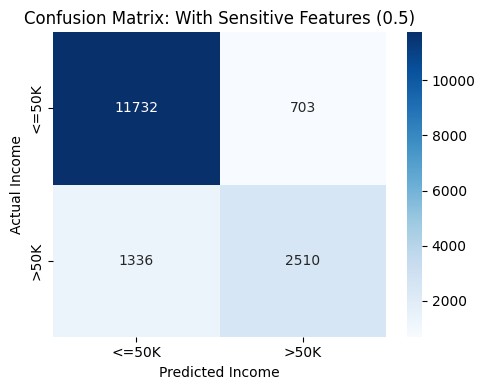

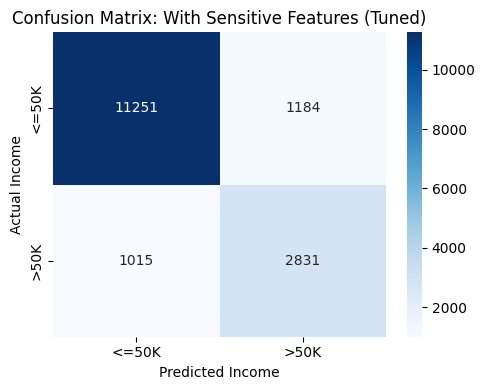

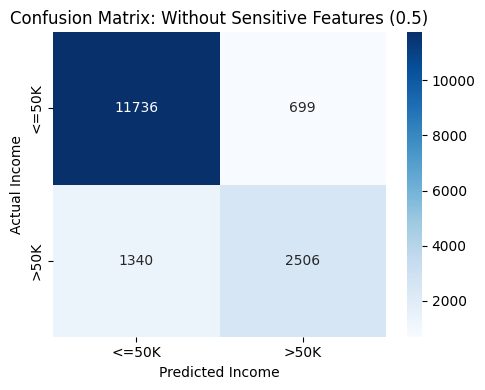

In [32]:
# CELL 3: Confusion matrices

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

predictions = {
    "With Sensitive Features (0.5)": test_pred_default,
    "With Sensitive Features (Tuned)": test_pred_tuned,
    "Without Sensitive Features (0.5)": test_pred_no_sensitive
}

for model_name, predictions_array in predictions.items():

    cm = confusion_matrix(y_test, predictions_array)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['<=50K', '>50K'],
        yticklabels=['<=50K', '>50K']
    )

    plt.title(f"Confusion Matrix: {model_name}")
    plt.xlabel("Predicted Income")
    plt.ylabel("Actual Income")
    plt.tight_layout()
    plt.show()

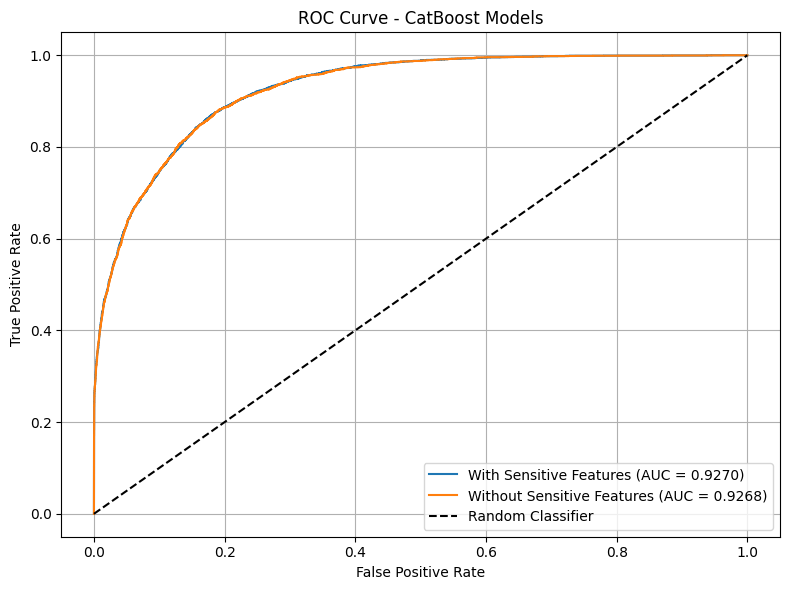

In [33]:
# CELL 4: ROC curve comparison

from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

model_probabilities = {
    "With Sensitive Features": test_prob,
    "Without Sensitive Features": test_prob_no_sensitive
}

for model_name, probabilities in model_probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr, tpr,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - CatBoost Models")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

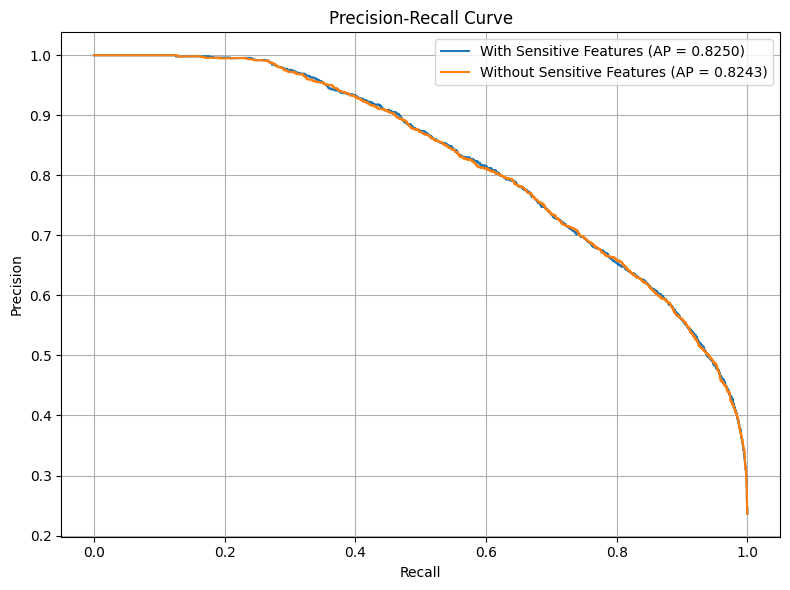

In [34]:
# CELL 5: Precision-Recall curves

from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for model_name, probabilities in model_probabilities.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test, probabilities
    )

    ap = average_precision_score(y_test, probabilities)

    plt.plot(
        recall, precision,
        label=f"{model_name} (AP = {ap:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [35]:
# CELL 6: Error analysis for the tuned model

error_analysis = X_test.copy()

error_analysis['Actual'] = np.asarray(y_test)
error_analysis['Predicted'] = np.asarray(test_pred_tuned)

error_analysis['Error Type'] = np.select(
    [
        (error_analysis['Actual'] == 0) &
        (error_analysis['Predicted'] == 1),

        (error_analysis['Actual'] == 1) &
        (error_analysis['Predicted'] == 0)
    ],
    ['False Positive', 'False Negative'],
    default='Correct'
)

print("Overall error counts:")
display(error_analysis['Error Type'].value_counts())

print("\nErrors by sex:")
display(pd.crosstab(
    error_analysis['sex'],
    error_analysis['Error Type']
))

print("\nErrors by race:")
display(pd.crosstab(
    error_analysis['race'],
    error_analysis['Error Type']
))

Overall error counts:


,count
Error Type,
Correct,14082
False Positive,1184
False Negative,1015



Errors by sex:


Error Type,Correct,False Negative,False Positive
sex,,,
Female,5067,193,161
Male,9015,822,1023



Errors by race:


Error Type,Correct,False Negative,False Positive
race,,,
Amer-Indian-Eskimo,145,6,8
Asian-Pac-Islander,402,33,45
Black,1445,66,50
Other,124,10,1
White,11966,900,1080


In [36]:
# CELL 7: Bootstrap confidence intervals for ROC-AUC and F1

from sklearn.metrics import roc_auc_score, f1_score
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, y_prob, n_iterations=1000):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)

    auc_scores = []
    f1_scores = []

    rng = np.random.default_rng(42)

    for i in range(n_iterations):

        indices = rng.integers(0, len(y_true), len(y_true))

        y_b = y_true[indices]
        pred_b = y_pred[indices]
        prob_b = y_prob[indices]

        # Skip samples containing only one class
        if len(np.unique(y_b)) < 2:
            continue

        auc_scores.append(roc_auc_score(y_b, prob_b))
        f1_scores.append(f1_score(y_b, pred_b, zero_division=0))

    return {
        'AUC Mean': np.mean(auc_scores),
        'AUC 95% CI Lower': np.percentile(auc_scores, 2.5),
        'AUC 95% CI Upper': np.percentile(auc_scores, 97.5),
        'F1 Mean': np.mean(f1_scores),
        'F1 95% CI Lower': np.percentile(f1_scores, 2.5),
        'F1 95% CI Upper': np.percentile(f1_scores, 97.5)
    }


bootstrap_results = []

models_for_bootstrap = [
    (
        "With Sensitive Features (0.5)",
        test_pred_default,
        test_prob
    ),
    (
        "With Sensitive Features (Tuned)",
        test_pred_tuned,
        test_prob
    ),
    (
        "Without Sensitive Features (0.5)",
        test_pred_no_sensitive,
        test_prob_no_sensitive
    )
]

for name, predictions_array, probabilities in models_for_bootstrap:

    result = bootstrap_ci(
        y_test,
        predictions_array,
        probabilities,
        n_iterations=1000
    )

    result['Model'] = name
    bootstrap_results.append(result)

bootstrap_table = pd.DataFrame(bootstrap_results)

display(bootstrap_table.round(4))

,AUC Mean,AUC 95% CI Lower,AUC 95% CI Upper,F1 Mean,F1 95% CI Lower,F1 95% CI Upper,Model
0,0.9270,0.9227,0.9313,0.7110,0.6987,0.7234,With Sensitive Features (0.5)
1,0.9270,0.9227,0.9313,0.7202,0.7090,0.7315,With Sensitive Features (Tuned)
2,0.9267,0.9224,0.9310,0.7107,0.6985,0.7225,Without Sensitive Features (0.5)


In [ ]:
# CELL 8: Save results

test_comparison.to_csv("test_model_comparison.csv", index=False)

sex_default.to_csv("fairness_sex_default.csv", index=False)
race_default.to_csv("fairness_race_default.csv", index=False)

sex_tuned.to_csv("fairness_sex_tuned.csv", index=False)
race_tuned.to_csv("fairness_race_tuned.csv", index=False)

sex_no_sensitive.to_csv("fairness_sex_without_sensitive.csv", index=False)
race_no_sensitive.to_csv("fairness_race_without_sensitive.csv", index=False)

bootstrap_table.to_csv("bootstrap_confidence_intervals.csv", index=False)

error_analysis.to_csv("test_error_analysis.csv", index=False)

print("All result files saved successfully.")